In [2]:
# Cell 1 — Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="darkgrid")
print("All libraries loaded ✅")

All libraries loaded ✅


In [3]:
# Cell 2 — Column names
cols = ['label',
        'lepton_pT', 'lepton_eta', 'lepton_phi',
        'missing_energy_magnitude', 'missing_energy_phi',
        'jet1pt', 'jet1eta', 'jet1phi', 'jet1b_tag',
        'jet2pt', 'jet2eta', 'jet2phi', 'jet2b_tag',
        'jet3pt', 'jet3eta', 'jet3phi', 'jet3b_tag',
        'jet4pt', 'jet4eta', 'jet4phi', 'jet4b_tag',
        'mjj', 'mjjj', 'mlv', 'mjlv', 'mbb', 'mwbb', 'mwwbb']

In [4]:
# Cell 3 — Load data (500K rows to start)
df = pd.read_csv('../data/HIGGS.csv', header=None, names=cols, nrows=500000)
print(f"Shape: {df.shape}")
df.head()

Shape: (500000, 29)


,label,lepton_pT,lepton_eta,lepton_phi,missing_energy_magnitude,missing_energy_phi,jet1pt,jet1eta,jet1phi,jet1b_tag,...,jet4eta,jet4phi,jet4b_tag,mjj,mjjj,mlv,mjlv,mbb,mwbb,mwwbb
0,1.0,0.869293,-0.635082,0.225690,0.327470,-0.689993,0.754202,-0.248573,-1.092064,0.000000,...,-0.010455,-0.045767,3.101961,1.353760,0.979563,0.978076,0.920005,0.721657,0.988751,0.876678
1,1.0,0.907542,0.329147,0.359412,1.497970,-0.313010,1.095531,-0.557525,-1.588230,2.173076,...,-1.138930,-0.000819,0.000000,0.302220,0.833048,0.985700,0.978098,0.779732,0.992356,0.798343
2,1.0,0.798835,1.470639,-1.635975,0.453773,0.425629,1.104875,1.282322,1.381664,0.000000,...,1.128848,0.900461,0.000000,0.909753,1.108330,0.985692,0.951331,0.803252,0.865924,0.780118
3,0.0,1.344385,-0.876626,0.935913,1.992050,0.882454,1.786066,-1.646778,-0.942383,0.000000,...,-0.678379,-1.360356,0.000000,0.946652,1.028704,0.998656,0.728281,0.869200,1.026736,0.957904
4,1.0,1.105009,0.321356,1.522401,0.882808,-1.205349,0.681466,-1.070464,-0.921871,0.000000,...,-0.373566,0.113041,0.000000,0.755856,1.361057,0.986610,0.838085,1.133295,0.872245,0.808487


In [5]:
df.shape          # how many rows and columns
df.dtypes         # data types
df.isnull().sum() # any missing values?
df.describe()     # min, max, mean, std of every feature

,label,lepton_pT,lepton_eta,lepton_phi,missing_energy_magnitude,missing_energy_phi,jet1pt,jet1eta,jet1phi,jet1b_tag,...,jet4eta,jet4phi,jet4b_tag,mjj,mjjj,mlv,mjlv,mbb,mwbb,mwwbb
count,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,...,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000
mean,0.529406,0.992273,-0.000556,-0.000553,0.997768,-0.001639,0.990045,-0.001745,0.000703,1.001603,...,-0.000402,-0.002381,0.997535,1.034436,1.024381,1.050658,1.009984,0.973398,1.033265,0.959862
std,0.499135,0.564812,1.007581,1.005965,0.599486,1.006992,0.474977,1.009909,1.006259,1.028063,...,1.008514,1.005571,1.399199,0.668159,0.377681,0.164500,0.397920,0.525703,0.364609,0.313198
min,0.000000,0.274697,-2.434976,-1.742508,0.000626,-1.743944,0.138602,-2.969725,-1.741237,0.000000,...,-2.497265,-1.742691,0.000000,0.107253,0.245318,0.092202,0.157473,0.048125,0.303350,0.350939
25%,0.000000,0.591302,-0.737349,-0.871931,0.576872,-0.873559,0.678626,-0.688235,-0.866988,0.000000,...,-0.715023,-0.873144,0.000000,0.790948,0.846149,0.985764,0.767660,0.673829,0.819699,0.770386
50%,1.000000,0.854469,-0.002002,0.000971,0.890737,-0.002751,0.894270,-0.002996,0.000058,1.086538,...,-0.001294,-0.005259,0.000000,0.895064,0.950312,0.989769,0.916798,0.873490,0.947297,0.871507
75%,1.000000,1.238057,0.738214,0.870439,1.291460,0.872038,1.169549,0.685214,0.869421,2.173076,...,0.714934,0.867721,3.101961,1.024465,1.083044,1.020365,1.142482,1.139608,1.140251,1.059291
max,1.000000,8.711782,2.434868,1.743236,9.900929,1.743251,8.382610,2.969674,1.741454,2.173076,...,2.498009,1.743372,3.101961,20.937159,10.474028,5.921233,10.468322,13.735691,8.432360,6.259156


In [6]:
df['label'].value_counts()
df['label'].value_counts(normalize=True)  # as percentages

label
1.0    0.529406
0.0    0.470594
Name: proportion, dtype: float64

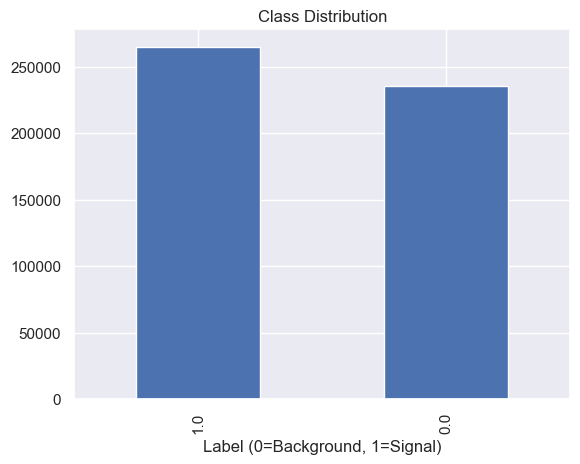

In [7]:
df['label'].value_counts().plot(kind='bar')
plt.title('Class Distribution')
plt.xlabel('Label (0=Background, 1=Signal)')
plt.savefig('../plots/class_distribution.png')
plt.show()

## Observation 1: Class Balance
The dataset is well balanced with approximately 53% background (label=0) 
and 47% signal (label=1). This means we do not need to apply any class 
balancing techniques such as oversampling or class weights. 
Accuracy is a reliable metric here alongside AUC-ROC.

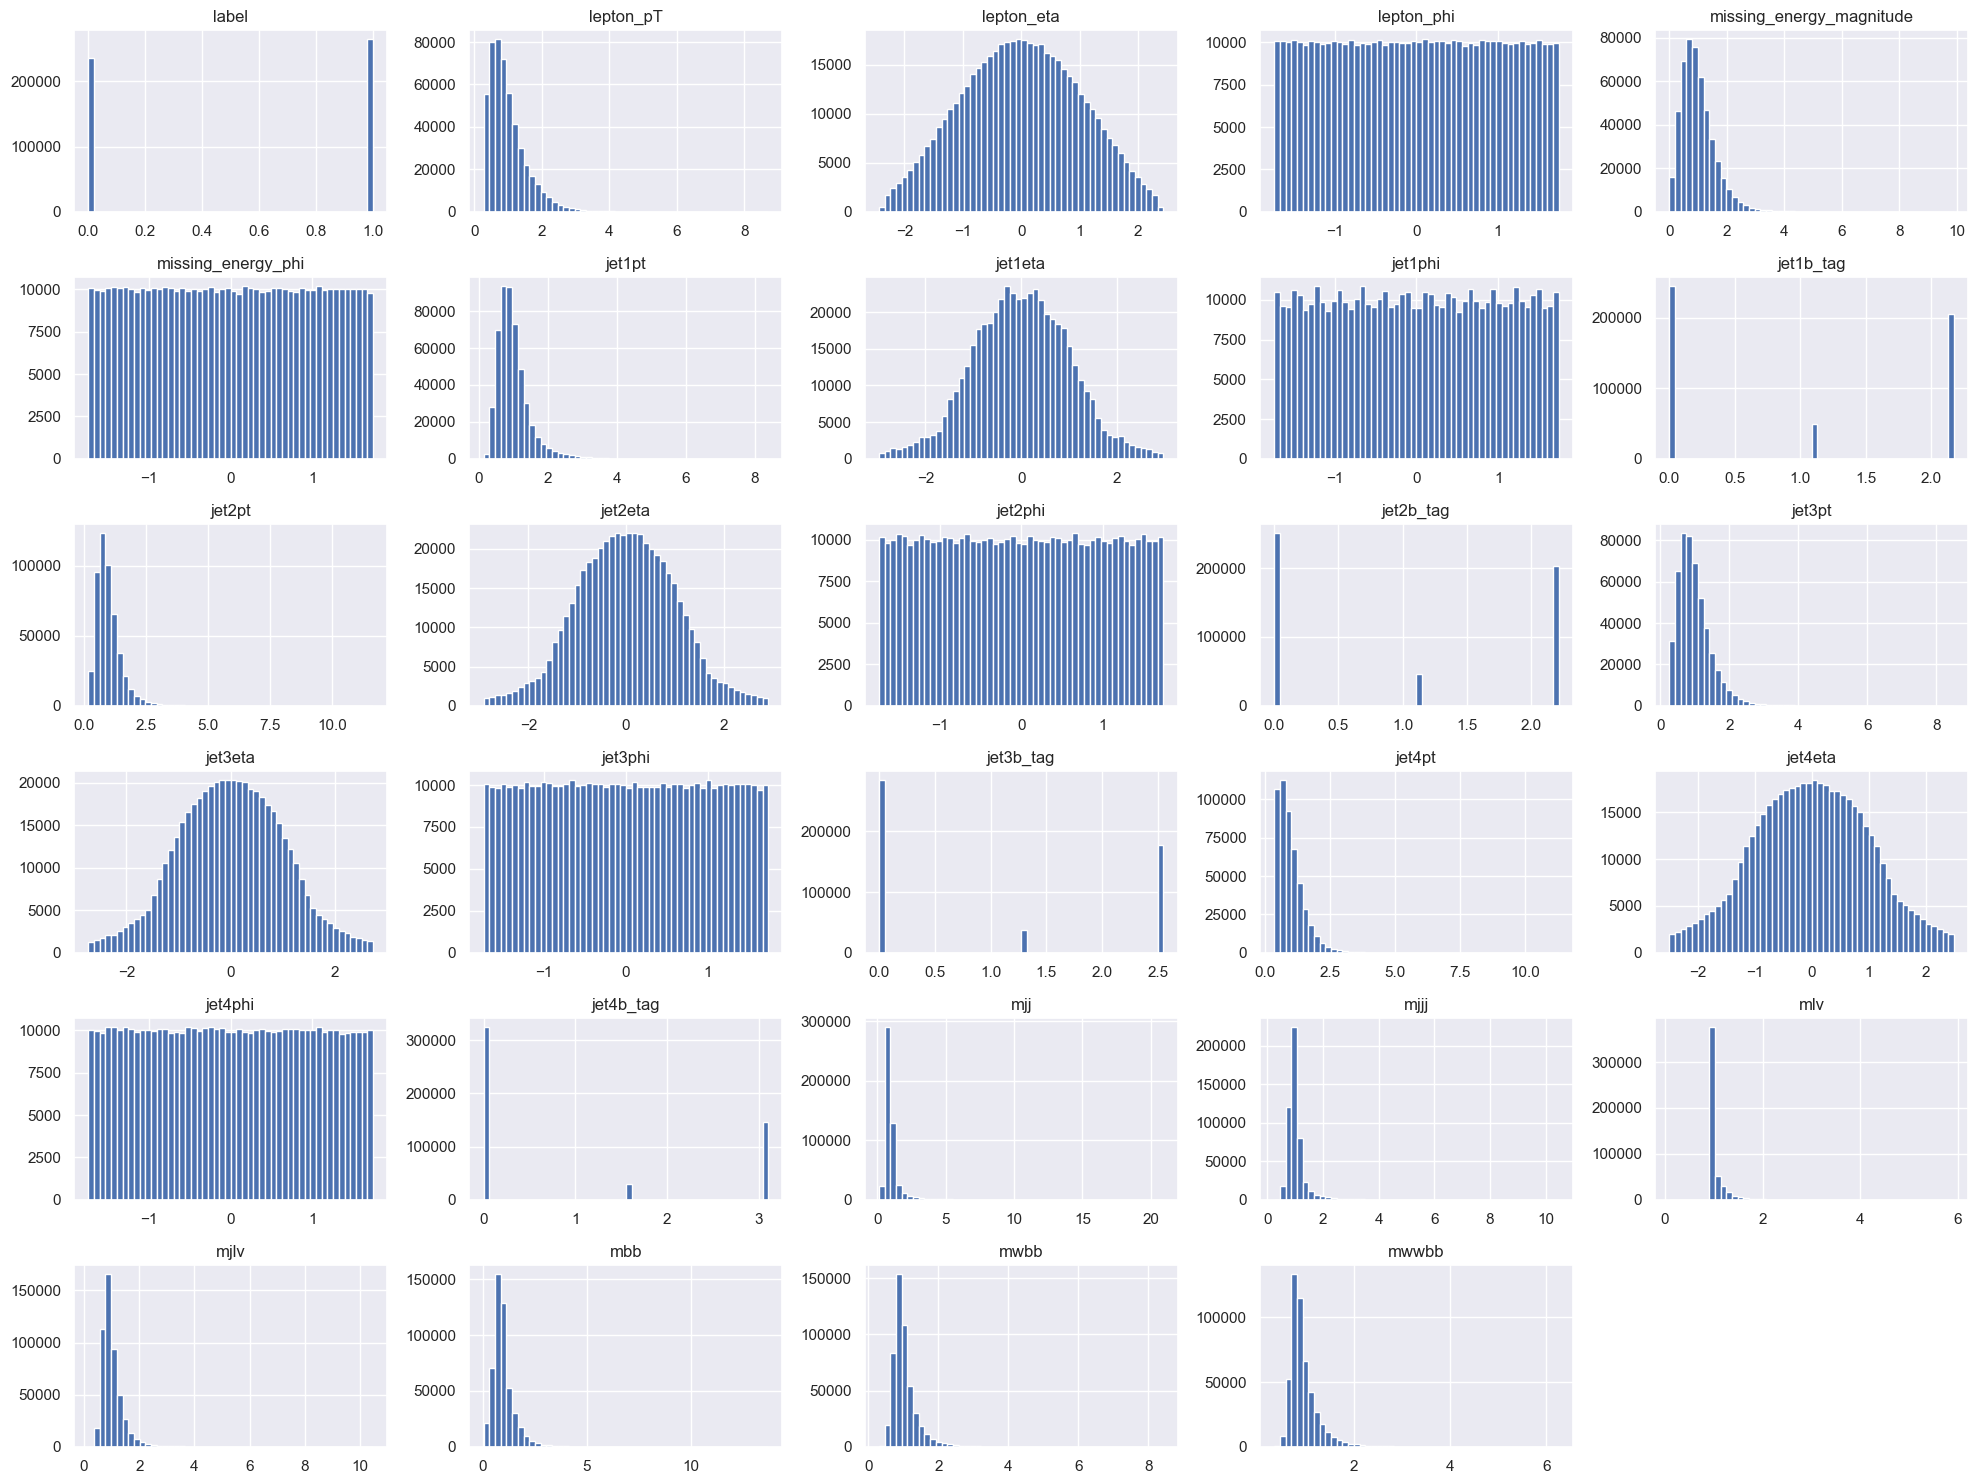

In [8]:
df.hist(figsize=(20, 15), bins=50)
plt.tight_layout()
plt.savefig('../plots/feature_distributions.png', dpi=150)
plt.show()

## Observation 2: Feature Distributions
Features fall into clearly distinct shape categories:

- **Momentum features** (lepton_pT, jet1pt, jet2pt, jet3pt, jet4pt, 
  missing_energy_magnitude) are right-skewed — most values are low 
  with a long tail toward higher energies. This is physically expected 
  as most particles are produced with moderate momentum.

- **Angular features** (lepton_eta, jet1eta, lepton_phi, jet1phi etc.) 
  are approximately symmetric and bell-shaped around zero, 
  reflecting the symmetric geometry of the detector.

- **b-tag features** (jet1b_tag, jet2b_tag, jet3b_tag, jet4b_tag) show 
  a highly unusual bimodal distribution — values cluster at 0 and ~2.17 
  with almost nothing in between. This is not a continuous measurement 
  but effectively a discrete tag indicating whether a jet was identified 
  as coming from a bottom quark.

- **High-level mass features** (mbb, mwbb, mwwbb, mlv) are tightly 
  concentrated near 1.0 with low spread (std ≈ 0.16–0.52), while mjj 
  and mjjj have much wider ranges (mjj max ~20.9), suggesting some 
  events produce very high invariant mass jet combinations.

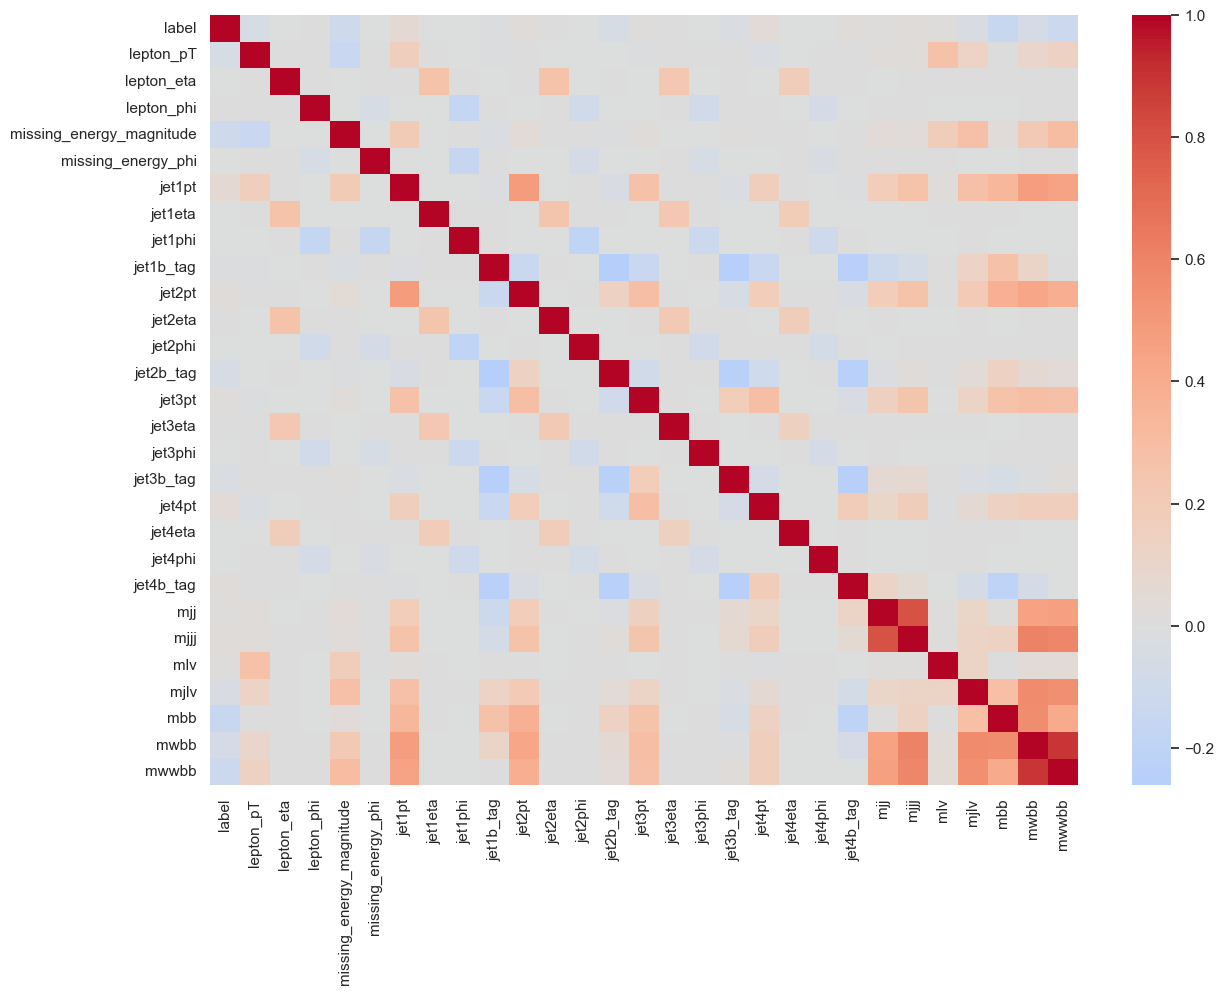

In [11]:
plt.figure(figsize=(14, 10))
sns.heatmap(df.corr(), cmap='coolwarm', center=0)
plt.savefig('../plots/correlation_heatmap.png', dpi=150)
plt.show()

In [28]:
signal = df[df['label'] == 1]
background = df[df['label'] == 0]

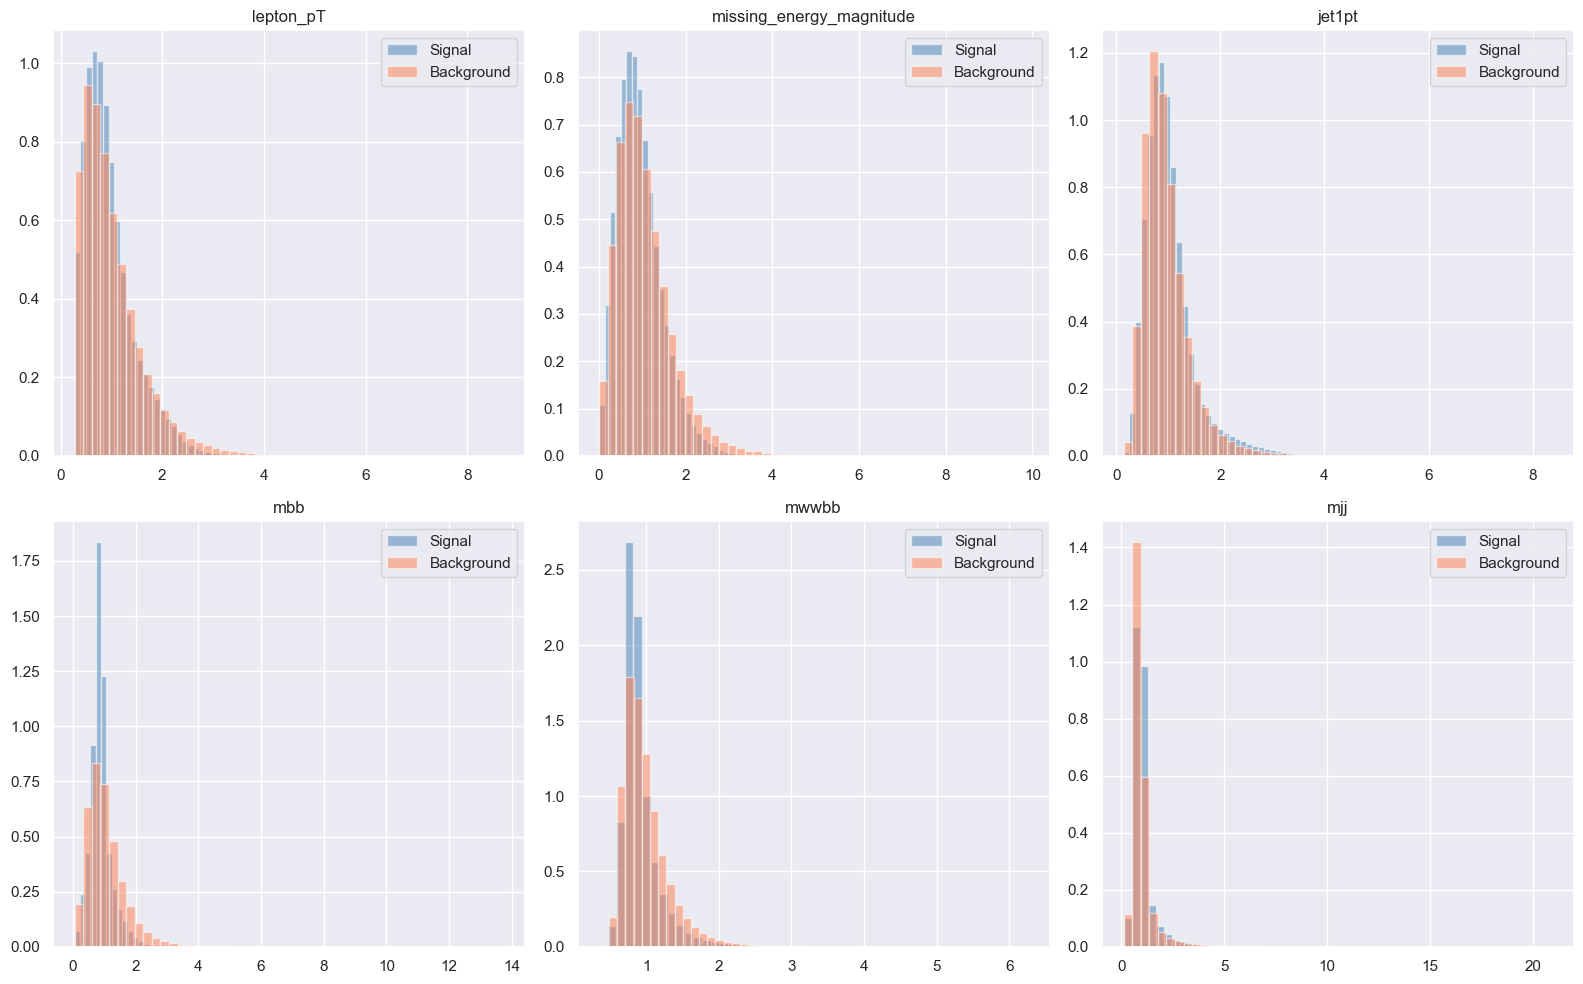

In [29]:
features_to_plot = [
    'lepton_pT',
    'missing_energy_magnitude',
    'jet1pt',
    'mbb',
    'mwwbb',      # most powerful single feature
    'mjj'
]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, feature in enumerate(features_to_plot):
    axes[i].hist(signal[feature], bins=50, alpha=0.5, 
                 label='Signal', color='steelblue', density=True)
    axes[i].hist(background[feature], bins=50, alpha=0.5, 
                 label='Background', color='coral', density=True)
    axes[i].set_title(feature)
    axes[i].legend()

plt.tight_layout()
plt.savefig('../plots/signal_vs_background.png', dpi=150)
plt.show()

## Observation 3: Signal vs Background Separability

The six features show varying degrees of separability between signal 
and background events:

- **lepton_pT**: Signal events (blue) are shifted slightly toward higher 
  transverse momentum compared to background. Both distributions are 
  right-skewed and largely overlapping, making this feature weakly 
  discriminating on its own.

- **missing_energy_magnitude**: Signal events show a heavier tail at 
  higher values compared to background. This makes physical sense — 
  Higgs decay produces neutrinos which carry away more invisible energy 
  in signal events.

- **jet1pt**: Very similar distributions for both classes with minimal 
  visible separation. The leading jet momentum alone is not a strong 
  discriminator.

- **mbb** (invariant mass of two b-tagged jets): Signal events show a 
  noticeably sharper peak near low values compared to the more spread 
  background distribution. This is one of the more separating low-to-mid 
  level features.

- **mwwbb** (full system invariant mass): Signal events are strongly 
  concentrated near 0.85–1.0, while background spreads more broadly. 
  This is the most visually separating feature of the six — consistent 
  with the literature which identifies mwwbb as the single most 
  discriminating feature in the dataset.

- **mjj** (dijet invariant mass): Both classes peak sharply near zero 
  but background has a significantly longer tail extending to ~20. 
  Signal events are more tightly confined to low mjj values.

**Key takeaway:** High-level engineered features (mwwbb, mbb) show 
stronger class separation than raw low-level features (lepton_pT, jet1pt). 
This motivates comparing models trained on low-level vs high-level 
features separately — a core experiment of this project.